# TP1 : les fondations du MLOps : rendre chaque expérience traçable, versionnée, visualisable et reproductible.

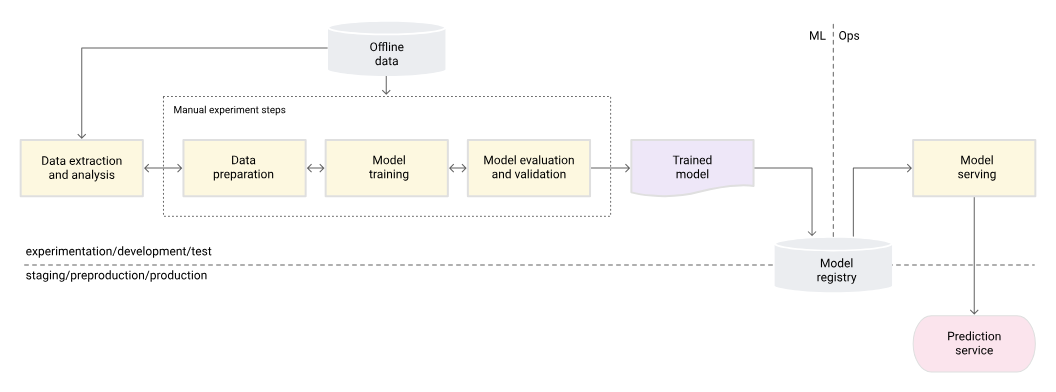


Le développement de modèles de machine learning ne se limite plus aujourd’hui à la simple création d’un algorithme capable de bien prédire sur un jeu de test. Dans un environnement de production réel, un modèle doit pouvoir être suivi, rejoué, amélioré, déployé et supervisé tout au long de son cycle de vie. C’est précisément dans cette perspective qu’est née la discipline du **MLOps** (Machine Learning Operations).

Le MLOps vise à appliquer les principes du DevOps au machine learning. Alors que le DevOps s’intéresse à l’intégration continue (CI) et au déploiement continu (CD) du code logiciel, le MLOps étend cette logique aux modèles et aux données. Il permet de gérer tout le **cycle de vie d’un projet de machine learning**, depuis la collecte des données jusqu’à la mise en production du modèle et à son suivi en conditions réelles.

Le schéma ci-dessus illustre une première version simplifiée du cycle MLOps, souvent appelée **niveau 0**, ou pipeline manuel. On y distingue plusieurs étapes essentielles :

1. **Data extraction and analysis** : phase où les données brutes sont collectées, nettoyées et analysées afin d’en comprendre la structure et la qualité.
2. **Data preparation** : préparation des données pour l’entraînement, incluant la normalisation, le découpage en ensembles d’entraînement et de test, ou encore la création de caractéristiques (features).
3. **Model training** : entraînement du modèle de machine learning à partir des données préparées, en ajustant les hyperparamètres.
4. **Model evaluation and validation** : évaluation des performances du modèle sur des données non vues et validation de sa robustesse.
5. **Model registry** : enregistrement du modèle entraîné et validé dans un registre centralisé, qui permet de conserver l’historique des versions et d’assurer la traçabilité.
6. **Model serving** : mise à disposition du modèle sous forme de service ou d’API, permettant de générer des prédictions sur de nouvelles données.
7. **Prediction service** : exploitation concrète du modèle en production pour servir des utilisateurs, des applications ou d’autres systèmes.

Dans ce schéma, la partie située à gauche représente les activités expérimentales et manuelles réalisées par le data scientist : extraction, préparation, entraînement et validation. Ces tâches sont souvent effectuées localement, sur des notebooks ou des scripts isolés.
La partie droite correspond aux premières étapes d’industrialisation : gestion des modèles, déploiement et prédiction. C’est à ce stade qu’interviennent les outils et les plateformes de MLOps.

Pour automatiser et documenter ces différentes étapes, plusieurs outils ont été développés dans l’écosystème MLOps. Parmi les plus connus, on peut citer **MLflow**, **Weights & Biases (W&B)**, **DVC**, **Kubeflow**, ou encore **ClearML**. Chacun d’eux offre des fonctionnalités de suivi des expériences, de gestion des données et des modèles, ou encore d’orchestration de pipelines.

Dans ce TP, nous utiliserons **ClearML**, une plateforme open-source légère et intégrée qui permet de mettre en œuvre de manière progressive les concepts fondamentaux du MLOps. ClearML offre une interface Web et une API Python simples à utiliser, tout en couvrant plusieurs aspects essentiels :

* le suivi des expériences (tracking des métriques, des paramètres et des artefacts) ;
* la gestion et la version des jeux de données ;
* le stockage et la comparaison des modèles ;
* l’orchestration de pipelines et l’exécution automatisée des tâches ;
* le déploiement et le monitoring des modèles en production.

Nous allons donc explorer le niveau 0 du MLOps, celui où toutes les étapes sont encore réalisées manuellement par le data scientist, mais où chaque expérience est désormais **traçable, reproductible et mesurable**.
L’objectif de cette séance est de comprendre comment ClearML permet de capturer, centraliser et visualiser toutes les informations relatives à un entraînement : paramètres d’entrée, métriques, graphiques, pertes, modèles sauvegardés et configurations associées.

Cette première approche pose les fondations de la démarche MLOps : elle montre comment passer d’un simple script expérimental à un projet structuré et suivi, ouvrant ensuite la voie à l’automatisation complète qui sera abordée dans les TP suivants.




# 1. Installation des dépendances

Cette cellule installe les bibliothèques nécessaires au TP et garantit que leur version est suffisamment récente pour éviter des incompatibilités fréquentes en environnement Colab.

In [ ]:
!pip -q install clearml torch torchvision matplotlib scikit-learn gradio --upgrade


: 

clearml : plateforme de suivi des expériences. Elle enregistre automatiquement hyperparamètres, métriques, artefacts et figures, puis les affiche dans un tableau de bord.

torch : cœur de PyTorch, utilisé pour définir les réseaux de neurones, gérer le calcul différentiable et l’entraînement sur CPU/GPU.

torchvision : utilitaires vision pour PyTorch (datasets comme CIFAR-10, modèles pré-définis, transformations d’images).

matplotlib : visualisation des courbes d’apprentissage, matrices de confusion, distributions de classes.

scikit-learn : métriques, utilitaires d’évaluation et prétraitements classiques (ex. accuracy, confusion_matrix).

gradio : création d’une interface Web simple pour tester le modèle en fin de TP (démonstration de “serving” interactif).

# 2. Initialisation du projet ClearML

Cette étape permet de connecter votre notebook Colab au serveur ClearML, afin de suivre automatiquement toutes les expériences et de centraliser les résultats dans un tableau de bord web.

La commande clearml-init configure votre environnement pour qu’il puisse communiquer avec le serveur ClearML.
Lors de son exécution, un assistant interactif s’ouvre dans le terminal et vous demande d'inserer les credentials.

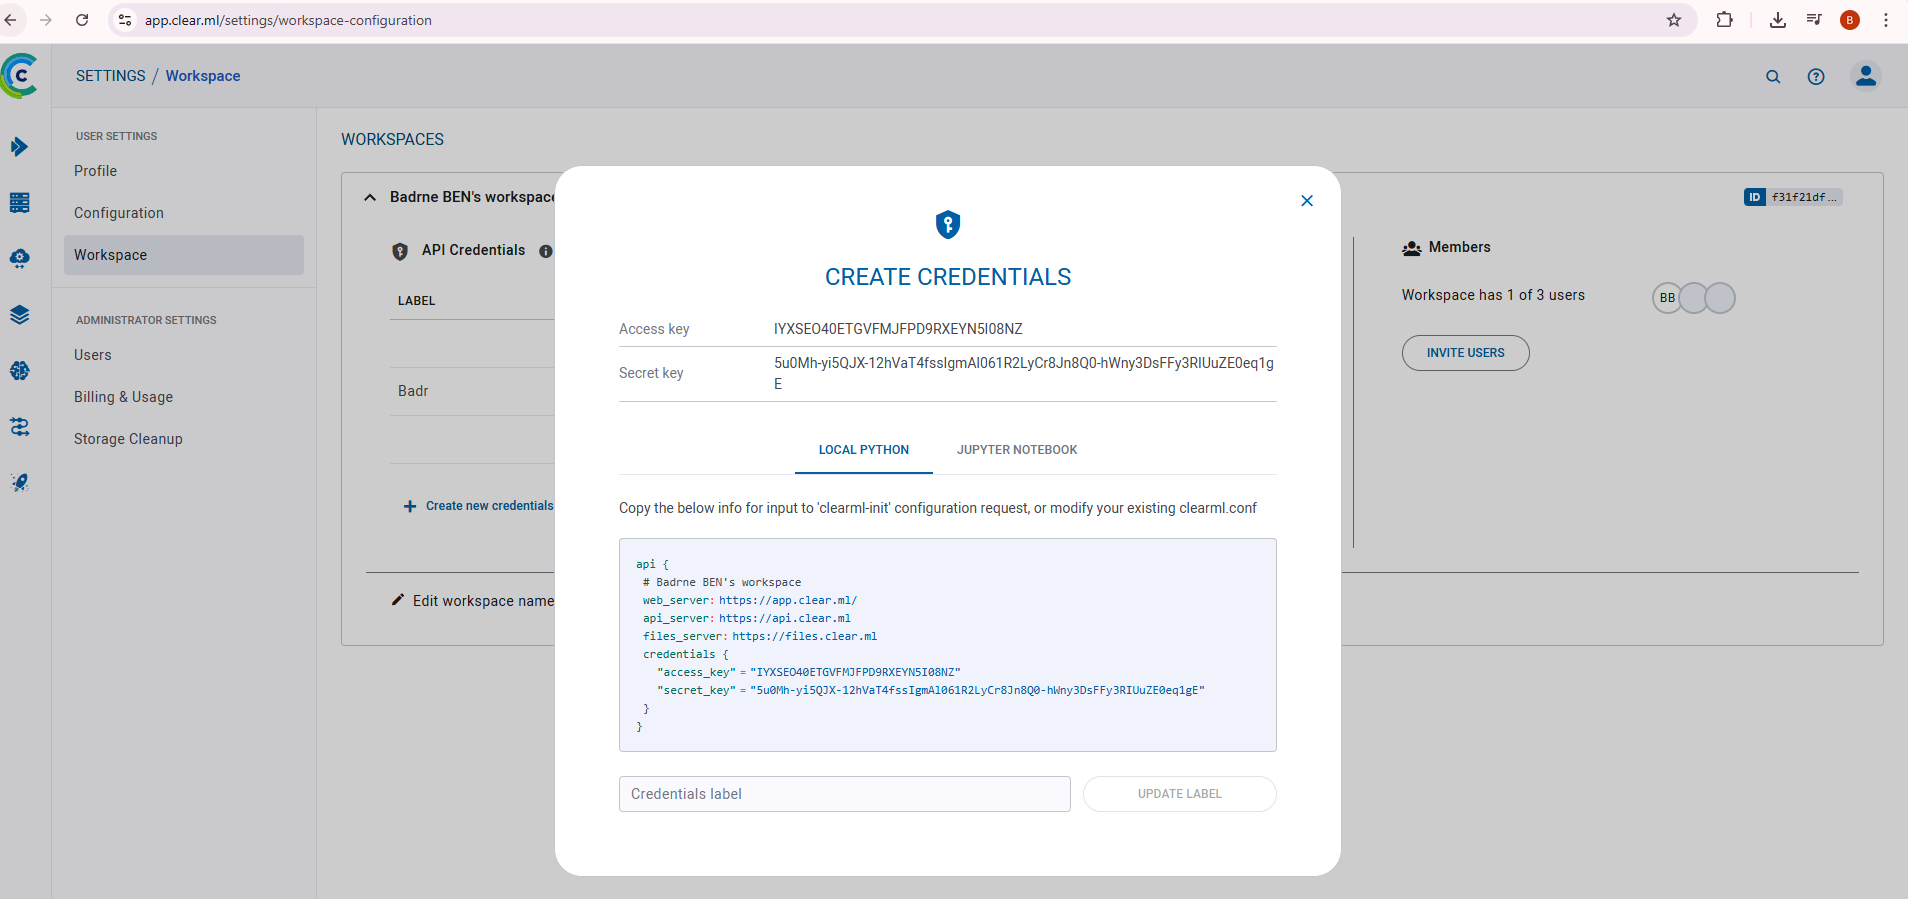

In [2]:
!clearml-init

ClearML SDK setup process

Please create new clearml credentials through the settings page in your `clearml-server` web app (e.g. http://localhost:8080//settings/workspace-configuration) 
Or create a free account at https://app.clear.ml/settings/workspace-configuration

In settings page, press "Create new credentials", then press "Copy to clipboard".

Paste copied configuration here:
api {   # Badrne BEN's workspace   web_server: https://app.clear.ml/   api_server: https://api.clear.ml   files_server: https://files.clear.ml   credentials {     "access_key" = "0BBPAV5GP06YF0RWHIZOG29SP3XTIO"     "secret_key" = "c7gSngrjUSVxIDlePi1idQysC84NmNz6Jl6HZoC1SzcpGcw6dQf2MqxrtSLfert4gt4"   } }
Detected credentials key="0BBPAV5GP06YF0RWHIZOG29SP3XTIO" secret="c7gS***"

ClearML Hosts configuration:
Web App: https://app.clear.ml/
API: https://api.clear.ml
File Store: https://files.clear.ml

Verifying credentials ...
Credentials verified!

New configuration stored in /root/clearml.conf
ClearML setup

# 3. Extraction et analyse initiale des données


Cette section a pour objectif de préparer et analyser le jeu de données CIFAR-10, tout en utilisant ClearML pour tracer automatiquement les opérations de traitement et de visualisation.
Elle illustre la première étape concrète du cycle MLOps : la traçabilité des données.
Avant tout apprentissage, un ingénieur machine learning doit comprendre la composition du dataset, vérifier sa cohérence et documenter ces observations dans le tableau de bord MLOps.

In [3]:
import torch, random, numpy as np, matplotlib.pyplot as plt
from torchvision import datasets, transforms
from clearml import Task, Logger

task = Task.init(project_name="TP1-MLOps-0-Vision", task_name="Task_ALL_In_One")
logger = Logger.current_logger()

seed = 42
random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

raw_transform = transforms.Compose([transforms.ToTensor()])
train_raw = datasets.CIFAR10(root="./data", train=True, download=True, transform=raw_transform)
test_raw  = datasets.CIFAR10(root="./data", train=False, download=True, transform=raw_transform)
classes = train_raw.classes

from collections import Counter
cnt = Counter([y for _,y in train_raw])
logger.report_text(f"Class distribution: {cnt}")


fig, axes = plt.subplots(2,5, figsize=(10,4))
for ax in axes.ravel():
    img, y = train_raw[random.randrange(len(train_raw))]
    ax.imshow(np.transpose(img.numpy(), (1,2,0)))
    ax.set_title(classes[y]); ax.axis("off")
logger.report_matplotlib_figure(title="sample_images", series="raw", figure=fig, iteration=0); plt.close(fig)
print("Extraction & analyse OK.")

ClearML Task: created new task id=35b76c85befd49b5a730035500db8ab4


/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)


2025-10-13 20:54:47,348 - clearml.Task - INFO - Storing jupyter notebook directly as code
ClearML results page: https://app.clear.ml/projects/87e1051afcc24bae91c1e74b10506f9e/experiments/35b76c85befd49b5a730035500db8ab4/output/log


100%|██████████| 170M/170M [00:07<00:00, 22.2MB/s]


Class distribution: Counter({6: 5000, 9: 5000, 4: 5000, 1: 5000, 2: 5000, 7: 5000, 8: 5000, 3: 5000, 5: 5000, 0: 5000})
Extraction & analyse OK.


## Explication détaillée

### 3.1 Initialisation d’une **Task ClearML**

```python
task = Task.init(project_name="TP1-MLOps-0-Vision", task_name="Task_ALL_In_One")
```

* **`Task.init()`** crée une *expérience traçable* dans ClearML, liée à un projet (ici *TP1-MLOps-0-Vision*).
* Cette expérience regroupe toutes les informations de cette étape : code exécuté, métriques, graphiques, versions de librairies, etc.
* L’argument `task_name` définit le nom de la tâche affichée dans le tableau de bord ClearML (ici : *Task_ALL_In_One*).
* Ce mécanisme permet de documenter automatiquement les résultats de la préparation des données, au même titre que ceux d’un entraînement de modèle.

### 3.2 Le **Logger** ClearML

```python
logger = Logger.current_logger()
```

* Le **Logger** est l’outil qui permet d’envoyer des informations au serveur ClearML.
* Il s’utilise comme une “console de suivi avancée” : tout ce qu’on y envoie (texte, graphes, figures, scalaires) devient visible dans l’interface ClearML.
* Chaque `logger` est lié à la tâche en cours (`Task.current_task()`).

Principales méthodes du logger :

| Méthode                      | Utilisation                                                             | Exemple                                                                       |
| ---------------------------- | ----------------------------------------------------------------------- | ----------------------------------------------------------------------------- |
| `report_text()`              | Enregistre un message, une remarque ou une statistique textuelle        | `logger.report_text("Dataset loaded")`                                        |
| `report_scalar()`            | Trace une valeur numérique (loss, accuracy, etc.) au fil des itérations | `logger.report_scalar("Loss", "train", loss, epoch)`                          |
| `report_matplotlib_figure()` | Enregistre un graphique Matplotlib complet                              | `logger.report_matplotlib_figure(title="sample", series="train", figure=fig)` |

Ces commandes seront utilisées à plusieurs reprises dans les TP pour suivre les métriques et visualiser les résultats.

---

### 3.3 Reproductibilité (fixer la *seed*)

```python
seed = 42
random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
```

* Les modèles de deep learning contiennent des composants aléatoires (initialisation des poids, ordre des batchs, etc.).
* Fixer une graine aléatoire (*seed*) assure la **reproductibilité** des expériences.
* Cette étape est fondamentale en MLOps, car elle permet de reproduire un résultat exactement, même des mois plus tard.

---

### 3.4 Téléchargement des données (CIFAR-10)

```python
train_raw = datasets.CIFAR10(root="./data", train=True, download=True, transform=raw_transform)
test_raw  = datasets.CIFAR10(root="./data", train=False, download=True, transform=raw_transform)
```

* Le dataset **CIFAR-10** contient 60 000 images 32×32 en couleur, réparties sur 10 classes (avion, chat, chien, etc.).
* L’argument `transform=transforms.ToTensor()` convertit les images PIL en tenseurs PyTorch.
* L’option `download=True` permet à PyTorch de télécharger automatiquement les fichiers si le dossier `./data` est vide.
* `train_raw.classes` retourne la liste des labels :
  `['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']`.

Cette extraction de données est manuelle (*offline extract*), mais elle est suivie dans ClearML pour garder une trace du contexte des futurs entraînements.

---

### 3.5 Analyse descriptive du dataset

#### a) Distribution des classes

```python
from collections import Counter
cnt = Counter([y for _,y in train_raw])
logger.report_text(f"Class distribution: {cnt}")
```

* Le `Counter` calcule combien d’images appartiennent à chaque classe.
* Le `logger.report_text()` envoie cette information dans ClearML (onglet *Text Output*).
* Cela documente la composition exacte du dataset utilisé pour cette expérience — pratique si la base est modifiée ultérieurement (par exemple, suppression d’images corrompues).

#### b) Visualisation d’échantillons

```python
fig, axes = plt.subplots(2,5, figsize=(10,4))
for ax in axes.ravel():
    img, y = train_raw[random.randrange(len(train_raw))]
    ax.imshow(np.transpose(img.numpy(), (1,2,0)))
    ax.set_title(classes[y]); ax.axis("off")
logger.report_matplotlib_figure(title="sample_images", series="raw", figure=fig, iteration=0)
```

* Cette portion affiche 10 images aléatoires issues du dataset.
* Chaque image est accompagnée de son étiquette (`classes[y]`).
* La figure est ensuite enregistrée dans ClearML grâce à `report_matplotlib_figure()`.
* L’argument `series="raw"` indique qu’il s’agit d’images issues des données brutes (avant normalisation ou augmentation).

Ce type de visualisation est un bon réflexe en MLOps : avant tout entraînement, il faut vérifier que les images, couleurs et labels sont corrects.




# 4. Préparation des données

(Data Preparation and Configuration Tracking)

Cette section correspond à la mise en forme du dataset avant l’entraînement.
L’objectif est double :

préparer les données de manière reproductible et cohérente (chargement, transformations, normalisation),

connecter tous les hyperparamètres de configuration à ClearML afin qu’ils soient visibles et modifiables directement depuis l’interface web.

In [4]:
from torch.utils.data import DataLoader

config = {
    "img_size": 32,
    "batch_size": 128,
    "num_workers": 2,
    "lr": 1e-3,
    "epochs": 5,          # Colab: 5–10 suffisent
    "weight_decay": 1e-4,
}
task.connect(config)   # visibles/modifiables dans l’UI

mean = (0.4914, 0.4822, 0.4465)
std  = (0.2470, 0.2435, 0.2616)
train_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
test_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_ds = datasets.CIFAR10("./data", train=True,  transform=train_tf)
test_ds  = datasets.CIFAR10("./data", train=False, transform=test_tf)

train_loader = DataLoader(train_ds, batch_size=config["batch_size"], shuffle=True,  num_workers=config["num_workers"])
test_loader  = DataLoader(test_ds,  batch_size=config["batch_size"], shuffle=False, num_workers=config["num_workers"])

print("Préparation OK.")


Préparation OK.



## Explication détaillée

### 4.1. Connexion des hyperparamètres à ClearML

```python
config = {
    "img_size": 32,
    "batch_size": 128,
    "num_workers": 2,
    "lr": 1e-3,
    "epochs": 5,
    "weight_decay": 1e-4,
}
task.connect(config)
```

* Le dictionnaire `config` regroupe tous les hyperparamètres liés à l’entraînement.
  Ces valeurs contrôlent la taille des lots (`batch_size`), le taux d’apprentissage (`lr`), le nombre d’époques, etc.
* L’appel `task.connect(config)` est une commande **propre à ClearML** :
  il enregistre ce dictionnaire dans l’interface du projet, onglet **“Configuration → Hyperparameters”**.
* ClearML permet ensuite :

  * de **visualiser ces paramètres** pour chaque expérience,
  * de les **modifier à distance** (par ex. relancer une expérience avec un `lr` différent sans changer le code).

Cette approche assure la **traçabilité complète des conditions expérimentales** : on sait précisément sous quelle configuration chaque modèle a été entraîné.

---

### 4.2. Normalisation et transformations

```python
mean = (0.4914, 0.4822, 0.4465)
std  = (0.2470, 0.2435, 0.2616)
train_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
test_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
```

* Les valeurs `mean` et `std` correspondent aux statistiques du dataset CIFAR-10.
  Elles permettent de **centrer et réduire** les pixels, ce qui stabilise l’apprentissage et accélère la convergence.
* Les transformations du *train set* introduisent une **augmentation de données** (data augmentation) :

  * `RandomHorizontalFlip()` : miroir aléatoire pour améliorer la robustesse aux orientations,
  * `RandomCrop(32, padding=4)` : recadrage aléatoire avec marge, simulant des légers décalages.
* Les images du *test set* ne subissent pas d’augmentation, seulement la normalisation.

Cette distinction entre transformations d’entraînement et de test est une **bonne pratique fondamentale** :
on veut enrichir la variété pendant l’apprentissage, mais évaluer sur des données “propres”.

---

### 4.3. Chargement et structuration avec DataLoader

```python
train_ds = datasets.CIFAR10("./data", train=True,  transform=train_tf)
test_ds  = datasets.CIFAR10("./data", train=False, transform=test_tf)
```

Ces deux objets représentent des **datasets PyTorch**.
Ils ne chargent pas encore les images en mémoire : ils fournissent une interface d’accès séquentiel via des *DataLoader*.

```python
train_loader = DataLoader(train_ds, batch_size=config["batch_size"], shuffle=True,  num_workers=config["num_workers"])
test_loader  = DataLoader(test_ds,  batch_size=config["batch_size"], shuffle=False, num_workers=config["num_workers"])
```

* Le **DataLoader** gère le découpage en mini-lots (*batches*) et le parallélisme de lecture des fichiers.
* Les arguments :

  * `batch_size` → taille des lots utilisés pendant l’apprentissage,
  * `shuffle=True` → mélange les données à chaque époque, évitant le surapprentissage à l’ordre des échantillons,
  * `num_workers` → nombre de processus parallèles pour accélérer le chargement (Colab : 2 suffit).


# 5. Entraînement du modèle

*(Model training with ClearML logging)*

Cette section met en place l’entraîneur pour un classifieur d’images sur CIFAR-10.
Elle illustre comment instrumenter la boucle d’entraînement et d’évaluation pour tracer automatiquement, dans ClearML, les métriques essentielles (perte et précision) à chaque époque.
Le choix d’un **ResNet-18** permet d’obtenir une base stable et rapide à entraîner dans un contexte pédagogique.




In [5]:
import torch.nn as nn, torch.optim as optim, os
from torchvision.models import resnet18
from clearml import Task, Logger

device = "cuda" if torch.cuda.is_available() else "cpu"
model = resnet18(num_classes=10).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=config["lr"], weight_decay=config["weight_decay"])

# Dossier local pour les checkpoints
os.makedirs("checkpoints", exist_ok=True)

# Reprise du dernier checkpoint si disponible
latest_ckpt = sorted([f for f in os.listdir("checkpoints") if f.endswith(".pt")])
if latest_ckpt:
    last_path = os.path.join("checkpoints", latest_ckpt[-1])
    model.load_state_dict(torch.load(last_path, map_location=device))
    print(f"Reprise du dernier checkpoint : {last_path}")

def train_one_epoch(epoch):
    model.train(); running_loss, correct, total = 0.0, 0, 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward(); optimizer.step()
        running_loss += loss.item() * x.size(0)
        pred = out.argmax(1)
        correct += (pred == y).sum().item(); total += y.size(0)
    train_loss = running_loss / total; train_acc = correct / total
    Logger.current_logger().report_scalar("loss", "train", train_loss, epoch)
    Logger.current_logger().report_scalar("accuracy", "train", train_acc, epoch)
    return train_loss, train_acc

@torch.no_grad()
def evaluate(epoch, loader=test_loader, split="val"):
    model.eval(); running_loss, correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x); loss = criterion(out, y)
        running_loss += loss.item() * x.size(0)
        pred = out.argmax(1); correct += (pred == y).sum().item(); total += y.size(0)
    loss = running_loss / total; acc = correct / total
    Logger.current_logger().report_scalar("loss", split, loss, epoch)
    Logger.current_logger().report_scalar("accuracy", split, acc, epoch)
    return loss, acc

# Entraînement avec sauvegarde systématique de chaque checkpoint
for ep in range(config["epochs"]):
    print(f"\n----- Époque {ep+1}/{config['epochs']} -----")
    tl, ta = train_one_epoch(ep)
    vl, va = evaluate(ep)

    # Sauvegarde locale
    ckpt_path = f"checkpoints/epoch_{ep:03d}.pt"
    torch.save(model.state_dict(), ckpt_path)

    # Upload dans ClearML (chaque epoch = artefact)
    task.upload_artifact(
        name=f"checkpoint_epoch_{ep:03d}",
        artifact_object=ckpt_path
    )
    Logger.current_logger().report_text(f"Checkpoint ClearML uploadé : {ckpt_path}")

print("Entraînement terminé : tous les checkpoints ont été enregistrés localement et sur ClearML.")



----- Époque 1/5 -----
Checkpoint ClearML uploadé : checkpoints/epoch_000.pt

----- Époque 2/5 -----
Checkpoint ClearML uploadé : checkpoints/epoch_001.pt

----- Époque 3/5 -----
Checkpoint ClearML uploadé : checkpoints/epoch_002.pt

----- Époque 4/5 -----
Checkpoint ClearML uploadé : checkpoints/epoch_003.pt

----- Époque 5/5 -----
Checkpoint ClearML uploadé : checkpoints/epoch_004.pt
Entraînement terminé : tous les checkpoints ont été enregistrés localement et sur ClearML.




##  Explication détaillée

### 5.1. Choix du modèle et du périphérique

* `resnet18(num_classes=10)` définit une architecture **résiduelle légère et efficace**, parfaitement adaptée à la tâche de classification d’images sur CIFAR-10 (10 classes).
* `device = "cuda" if torch.cuda.is_available() else "cpu"` permet d’utiliser le **GPU si disponible**, sinon le CPU.
* `model.to(device)` déplace les poids du réseau vers le périphérique sélectionné pour accélérer les calculs.

Cette étape garantit que le modèle est correctement initialisé et prêt à être entraîné sur la configuration matérielle de l’étudiant (GPU Colab, machine locale, etc.).

---

### 5.2. Fonction de perte et optimiseur

* `nn.CrossEntropyLoss()` est utilisée pour la **classification multiclasse**, mesurant l’écart entre les probabilités prédites et les vraies étiquettes.
* `optim.Adam(...)` est un optimiseur adaptatif qui ajuste automatiquement le taux d’apprentissage de chaque paramètre.
  Il reçoit :

  * `lr=config["lr"]` (taux d’apprentissage fixé dans la configuration connectée à ClearML),
  * `weight_decay=config["weight_decay"]` pour la **régularisation L2**, limitant le surapprentissage.

Les hyperparamètres de cette section sont **connectés à ClearML** via `task.connect(config)` (section précédente), ce qui permet de retracer et modifier facilement les paramètres d’expérimentation depuis l’interface ClearML.

---

### 5.3. Boucle d’entraînement instrumentée

* `model.train()` active le **mode entraînement**, nécessaire pour des couches comme BatchNorm ou Dropout.
* Pour chaque mini-lot d’images :

  * on **remet les gradients à zéro** (`optimizer.zero_grad()`),
  * on effectue une **propagation avant** (`out = model(x)`),
  * on calcule la **perte** (`loss = criterion(out, y)`),
  * on exécute la **rétropropagation** (`loss.backward()`) et la **mise à jour des poids** (`optimizer.step()`),
  * puis on **cumule les statistiques** (perte moyenne, taux de précision).

En fin d’époque, les moyennes sont calculées et **enregistrées dans ClearML** :

```python
Logger.current_logger().report_scalar("loss", "train", train_loss, epoch)
Logger.current_logger().report_scalar("accuracy", "train", train_acc, epoch)
```

Ces courbes sont visibles dans l’onglet **Scalars** du tableau de bord ClearML.
Elles permettent de suivre la progression du modèle et de détecter rapidement un surapprentissage.

---

### 5.4. Boucle d’évaluation instrumentée

* Le décorateur `@torch.no_grad()` désactive le calcul du gradient pour réduire la consommation mémoire et accélérer l’inférence.
* `model.eval()` impose un comportement **déterministe** pour les couches qui se comportent différemment à l’inférence (comme Dropout).
* Sur le jeu de validation ou de test, le script calcule :

  * la **perte moyenne** (`loss`),
  * la **précision globale** (`acc`),
  * puis les enregistre dans ClearML :

```python
Logger.current_logger().report_scalar("loss", "val", loss, epoch)
Logger.current_logger().report_scalar("accuracy", "val", acc, epoch)
```

Ces métriques apparaissent dans les mêmes graphiques que celles d’entraînement, permettant une **comparaison directe train/val**.

---

### 5.5. Sauvegarde et suivi des checkpoints

Contrairement à une approche classique où seul le “meilleur modèle” est conservé, ce TP met en œuvre un **enregistrement systématique de tous les checkpoints**.
À la fin de chaque époque :

```python
ckpt_path = f"checkpoints/epoch_{ep:03d}.pt"
torch.save(model.state_dict(), ckpt_path)
task.upload_artifact(name=f"checkpoint_epoch_{ep:03d}", artifact_object=ckpt_path)
Logger.current_logger().report_text(f"Checkpoint ClearML uploadé : {ckpt_path}")
```

**Explication :**

* Les poids du modèle (`state_dict`) sont sauvegardés localement dans `./checkpoints`.
* Puis, chaque fichier `.pt` est **envoyé dans ClearML** comme **artefact d’expérience**.
* Un message est ajouté dans les logs ClearML pour tracer l’opération.

Cela permet :

* de **visualiser chaque version du modèle** depuis le tableau de bord ClearML (onglet *Artifacts*),
* de **relancer un entraînement à partir d’un checkpoint précis**,
* et de **comparer a posteriori** la performance des différentes époques.

Ce comportement illustre parfaitement la philosophie du MLOps :

> *"Tout modèle produit pendant le cycle d’apprentissage doit être traçable, versionné et reproductible."*


# 6. Évaluation et validation du modèle

(Model evaluation and validation — Confusion Matrix)

Cette étape complète l’entraînement par une évaluation qualitative et par classe.
La matrice de confusion indique, pour chaque classe réelle, la manière dont le modèle répartit ses prédictions.
C’est un outil essentiel pour détecter des erreurs systématiques (par exemple, confusions récurrentes entre “chat” et “chien”), des classes sous-performantes, ou des biais liés au dataset.
Nous journalisons la figure dans ClearML afin de garder une trace visuelle du comportement du modèle pour ce run.

In [6]:
import itertools
from sklearn.metrics import confusion_matrix
import numpy as np

@torch.no_grad()
def eval_confusion():
    model.eval(); all_y, all_p = [], []
    for x,y in test_loader:
        x = x.to(device)
        p = model(x).argmax(1).cpu().numpy()
        all_p.extend(p); all_y.extend(y.numpy())
    cm = confusion_matrix(all_y, all_p, labels=list(range(10)))
    return cm

cm = eval_confusion()

# plot
fig, ax = plt.subplots(figsize=(6,6))
im = ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
ax.figure.colorbar(im, ax=ax)
tick_marks = np.arange(len(classes))
ax.set(xticks=tick_marks, yticks=tick_marks, xticklabels=classes, yticklabels=classes,
       ylabel='True', xlabel='Predicted', title="Confusion Matrix")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
    ax.text(j, i, format(cm[i, j], 'd'), ha="center", va="center",
            color="white" if cm[i, j] > cm.max()/2. else "black")
plt.tight_layout()
logger.report_matplotlib_figure(title="confusion_matrix", series="val", figure=fig, iteration=0); plt.close(fig)
print("Validation OK.")


Validation OK.



## Explication détaillée

**Collecte des prédictions.**
La fonction `eval_confusion()` bascule le modèle en mode évaluation (`model.eval()`), désactive le calcul de gradient (`@torch.no_grad()`), puis parcourt `test_loader`.
Pour chaque batch, elle calcule les classes prédites par `argmax(1)` et accumule à la fois les étiquettes vraies (`all_y`) et les étiquettes prédites (`all_p`).
La matrice de confusion `cm` est générée par `sklearn.metrics.confusion_matrix`, en fixant explicitement l’ordre des labels `labels=list(range(10))`.
Cela garantit la cohérence des indices de classes avec `classes`.

**Interprétation de la matrice.**

* Les **lignes** correspondent aux **classes réelles**.
* Les **colonnes** correspondent aux **classes prédites**.
* La **diagonale** contient les prédictions correctes.
* Les **valeurs hors diagonale** sont les confusions.
  Une diagonale forte et des valeurs faibles ailleurs indiquent un classifieur performant.
  Des colonnes dominantes ou des lignes “vides” révèlent des biais ou des classes difficiles.

**Traçabilité ClearML.**
La figure est envoyée au tableau de bord via `logger.report_matplotlib_figure(...)`.
Elle restera attachée à la Task courante, dans l’onglet **Plots**, ce qui permet de la comparer entre différents runs (utile lors du benchmark d’architectures).


# 7. Enregistrement du modèle dans le **Model Registry**

*(Model versioning and artifact management with ClearML)*

Une fois le modèle entraîné et évalué, la dernière étape du cycle MLOps niveau 0 consiste à **sauvegarder et versionner le modèle**.
ClearML propose un mécanisme intégré, le **Model Registry**, permettant de :

* centraliser toutes les versions de modèles produits au cours des expériences,
* conserver leurs poids, métadonnées, et liens avec les tâches d’origine,
* identifier facilement le “meilleur modèle” d’un projet, prêt pour le déploiement ou la réutilisation.



In [7]:
from clearml import OutputModel

# attache le meilleur poids comme artefact + modèle sorti
task.upload_artifact("best_checkpoint", artifact_object="best_resnet18_cifar10.pt")

# Model registry (option simple via OutputModel)
output_model = OutputModel(task=task, name="resnet18_cifar10_tp1")
output_model.update_weights("best_resnet18_cifar10.pt")
output_model.publish()   # rend la version visible/"locked" dans le registry

logger.report_text(f"Model published: {output_model.id}")
print("Modèle publié dans le Model Registry ClearML.")


2025-10-13 20:58:12,743 - clearml.model - INFO - No output storage destination defined, registering local model best_resnet18_cifar10.pt
Model published: 8a131879d9a54f469c147a7bf62fb5dd
Modèle publié dans le Model Registry ClearML.



## Explication détaillée

### 7.1. Sauvegarde d’un artefact

```python
task.upload_artifact("best_checkpoint", artifact_object="best_resnet18_cifar10.pt")
```

* Cette commande envoie le fichier `best_resnet18_cifar10.pt` (poids sauvegardés du meilleur modèle) vers le tableau de bord ClearML.
* L’artefact devient visible dans l’onglet **Artifacts** de la tâche associée.
* L’intérêt de cette étape est de conserver un lien direct entre la version du modèle et les métriques, les hyperparamètres et les données qui ont conduit à sa création.
* Les artefacts peuvent être téléchargés depuis l’interface ClearML ou utilisés dans d’autres environnements pour reproduction ou comparaison.

---

### 7.2. Publication dans le **Model Registry**

```python
output_model = OutputModel(task=task, name="resnet18_cifar10_tp1")
output_model.update_weights("best_resnet18_cifar10.pt")
output_model.publish()
```

* **`OutputModel`** représente la sortie officielle d’un entraînement, c’est-à-dire un modèle considéré comme stable ou prêt à être réutilisé.
* Le constructeur prend deux arguments :

  * `task` : la tâche d’où provient ce modèle (assurant la traçabilité complète),
  * `name` : le nom sous lequel le modèle apparaîtra dans le **Model Registry**.

#### Étapes principales :

1. **Création de l’objet modèle.**
   Cela lie le modèle au contexte de la tâche (`task`) déjà enregistrée dans ClearML.
2. **Mise à jour des poids.**
   L’appel à `update_weights("...pt")` envoie le fichier contenant les poids du modèle (ici le meilleur checkpoint) vers le serveur.
3. **Publication.**
   `publish()` verrouille la version du modèle et la rend visible dans la section **Models > Registry** de ClearML.
   Le modèle publié devient immuable : ses poids et métadonnées sont gelés.

Le résultat est une version identifiable par un ID unique (`output_model.id`), que l’on peut réutiliser ultérieurement pour :

* le déploiement dans une application (ex. via API ou agent ClearML),
* un benchmark automatique,
* une régression test lors de futures versions de modèles.

---

### 7.3. Journalisation dans ClearML

```python
logger.report_text(f"Model published: {output_model.id}")
```

* Ce texte sera visible dans l’onglet **Text Output** du tableau de bord.
* Il permet de consigner la confirmation de publication et l’ID du modèle pour traçabilité.
* Il sert également de référence pour relier le modèle publié à une expérience précise.



# 8. Service de modèle et service de prédiction

*(Model serving + Prediction service avec Gradio en Colab)*

Cette section transforme le modèle entraîné en un **service interactif**.
L’objectif est double :

1. **recharger** le meilleur checkpoint produit à l’étape précédente,
2. **exposer** une fonction de prédiction via une interface Web simple à l’aide de **Gradio**.

Dans le cycle MLOps niveau 0, cela correspond aux blocs « Model serving » puis « Prediction service » de la figure : le modèle est chargé en mémoire dans un petit service applicatif, et l’utilisateur soumet des images pour obtenir des prédictions.




In [10]:
import gradio as gr
from PIL import Image
import torchvision.transforms as T

# recharger le modèle publié (localement on re-lit le checkpoint)
model2 = resnet18(num_classes=10).to(device)
model2.load_state_dict(torch.load("/content/checkpoints/epoch_004.pt", map_location=device))
model2.eval()

infer_tf = T.Compose([T.Resize((32,32)), T.ToTensor(), T.Normalize(mean, std)])

@torch.no_grad()
def predict_image(img: Image.Image):
    x = infer_tf(img.convert("RGB")).unsqueeze(0).to(device)
    logits = model2(x).softmax(dim=1).cpu().numpy()[0]
    # top-3
    topk = np.argsort(logits)[::-1][:3]
    return {classes[i]: float(logits[i]) for i in topk}

demo = gr.Interface(
    fn=predict_image,
    inputs=gr.Image(type="pil", label="Upload CIFAR-like 32x32 (ou n'importe, redimensionné)"),
    outputs=gr.Label(num_top_classes=3),
    title="CIFAR-10 Classifier (TP1)",
    description="ResNet18 entraîné manuellement, traçable via ClearML. Colab → share=True pour lien public."
)

demo.launch(share=True)   # ⬅️ lien public temporaire


2025-10-13 20:59:06,438 - clearml.model - INFO - Selected model id: 0d5e2d443b3d430cb2ce5c5780500971


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://110dfeb61dd08dd765.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)



## Explication détaillée

1. **Chargement du modèle pour l’inférence.**
   On instancie la même architecture (`resnet18(num_classes=10)`) et on recharge les **poids du meilleur checkpoint** via `load_state_dict(...)`. Le modèle est déplacé sur `device` (GPU si disponible), puis passé en mode évaluation avec `model2.eval()` pour désactiver dropout et figer batch norm.

2. **Pipeline d’inférence cohérent avec l’entraînement.**
   Le transform `infer_tf` applique **redimensionnement 32×32**, **conversion en tenseur** et **normalisation** avec les mêmes `mean` et `std` que ceux utilisés à l’entraînement. Cette cohérence est indispensable pour éviter une chute artificielle des performances.

3. **Fonction de prédiction.**
   La fonction `predict_image` effectue :

   * préparation de l’image (`convert("RGB")`, `infer_tf`, ajout d’une dimension batch),
   * passage avant du réseau,
   * conversion en probabilités (`softmax`) et extraction du **Top-3** avec les libellés `classes`.
     L’annotation `@torch.no_grad()` évite le calcul de gradients, allégeant l’inférence.

4. **Interface Gradio.**
   `gr.Interface` associe la fonction Python `fn=predict_image` à une **entrée image** et une **sortie étiquettes**.
   `launch(share=True)` génère un **lien public temporaire** utilisable depuis un navigateur pour tester le modèle.

---

## Tests et validation rapide

* Envoyez une image représentative de CIFAR-10 (avion, chat, chien, etc.).
* Vérifiez que les **trois meilleures classes** retournées ont du sens et que les probabilités s’additionnent à 1 pour l’ensemble des 10 classes (la sortie Gradio n’affiche que le Top-3, mais le vecteur complet somme à 1).


# **Conclusion**

Cette première partie du TP avait pour objectif de faire découvrir **les fondements pratiques du MLOps** à travers un projet complet de classification d’images sur CIFAR-10, intégrant l’outil **ClearML** comme environnement central de suivi et de gestion des expériences.

---

## **1. Compréhension du MLOps : de la théorie à la pratique**

Le **MLOps** (Machine Learning Operations) vise à appliquer les principes de l’ingénierie logicielle — tels que la **traçabilité**, la **reproductibilité**, l’**automatisation** et le **déploiement continu** — au cycle de vie complet d’un modèle d’apprentissage automatique.
L’idée principale est que l’IA ne se limite pas à entraîner un modèle, mais qu’elle s’inscrit dans un **processus itératif, collaboratif et contrôlé**, garantissant la qualité et la fiabilité des systèmes déployés.

Dans cette Partie 1, les étudiants ont mis en œuvre un **pipeline MLOps minimal** (dit *niveau 0*), qui comprend les étapes suivantes :

* Préparation et exploration des données,
* Entraînement instrumenté du modèle,
* Évaluation et visualisation des métriques,
* Sauvegarde systématique des checkpoints,
* Journalisation et traçabilité complète via ClearML.

Ce cycle permet de **passer d’un entraînement local artisanal** à une **expérimentation structurée et traçable**, première pierre d’un système MLOps complet.

---

## **2. Les fonctions clés explorées dans ClearML**

ClearML a servi ici de **catalyseur pratique** pour introduire les grands principes du MLOps à travers des outils simples mais puissants :

| Fonction ClearML                                                              | Rôle dans le cycle MLOps                                                        | Impact pédagogique                                                          |
| ----------------------------------------------------------------------------- | ------------------------------------------------------------------------------- | --------------------------------------------------------------------------- |
| **`Task.init()`**                                                             | Démarre une tâche d’expérimentation, crée le contexte de tracking               | Rend chaque exécution identifiable, comparable et historisée                |
| **`task.connect(config)`**                                                    | Enregistre la configuration et les hyperparamètres du run                       | Permet la reproductibilité exacte d’un entraînement                         |
| **`Logger.report_scalar()` / `report_text()` / `report_matplotlib_figure()`** | Suivi des métriques et des graphiques                                           | Visualisation en temps réel de l’évolution du modèle                        |
| **`task.upload_artifact()`**                                                  | Sauvegarde et versionne les artefacts produits (checkpoints, figures, rapports) | Garantit la conservation et la réutilisation des résultats                  |
| **Dashboard ClearML**                                                         | Interface web pour comparer, trier et analyser les expériences                  | Crée un pont entre le développement individuel et la collaboration d’équipe |

Grâce à ces fonctionnalités, les étudiants ont vu comment un outil comme ClearML transforme un simple notebook PyTorch en **expérience MLOps complète**, sans modifier la logique scientifique du code.

---

## **3. Les apports concrets de ce premier niveau MLOps**

* **Traçabilité complète** : chaque exécution, métrique, paramètre et fichier est historisé automatiquement.
* **Reproductibilité garantie** : la combinaison du tracking ClearML et des seeds fixes permet de reproduire à l’identique un run d’entraînement.
* **Centralisation des résultats** : toutes les expériences sont accessibles depuis un tableau de bord unique, facilitant la comparaison entre versions.
* **Préparation au déploiement** : les checkpoints enregistrés à chaque époque servent de base au futur *serving* ou à la relance d’entraînements.

Cette méthodologie renforce la rigueur scientifique et met en évidence la **transition entre le Machine Learning artisanal et l’industrialisation de l’IA.**

---

## **4. Les limites du MLOps Niveau 0**

Malgré ses apports, ce premier niveau présente plusieurs **limites structurelles** :

| Limite                                                       | Description                                                                               | Conséquence                                            |
| ------------------------------------------------------------ | ----------------------------------------------------------------------------------------- | ------------------------------------------------------ |
| **Exécution manuelle**                                       | Toutes les étapes sont déclenchées depuis le notebook (aucune orchestration automatisée). | Difficulté à répliquer ou planifier les entraînements. |
| **Absence de pipeline**                                      | Les dépendances entre étapes (data → train → eval) ne sont pas formalisées.               | Impossibilité d’automatiser le flux complet.           |
| **Pas de détection d’anomalies ni de monitoring en continu** | L’évaluation se fait ponctuellement.                                                      | Aucun suivi en production.                             |
| **Pas de versioning du code/dataset dans ClearML Dataset**   | Les datasets sont statiques.                                                              | Risque d’incohérence si les données évoluent.          |
| **Déploiement manuel**                                       | Le modèle est servi via Gradio sans intégration continue (CI/CD).                         | Pas de pipeline de production stable.                  |

En d’autres termes, le MLOps 0 correspond à une **industrialisation minimale** : chaque composant du pipeline est traçable, mais l’ensemble reste encore **manuel et déconnecté**.
Dans le TP2, nous verrons comment ClearML permet de franchir cette étape en introduisant l’orchestration automatique (pipelines ClearML), les agents d’exécution et les tâches interconnectées, ainsi que le continuous training : le pipeline se relance automatiquement lorsqu’une nouvelle version de données est disponible (ou lorsqu’un seuil de qualité n’est pas atteint). Nous relierons la préparation, l’entraînement et la validation dans un flux automatisé, capable d’évaluer plusieurs modèles en parallèle et, une fois validés, de promouvoir la bonne version vers le Model Registry.

Cette deuxième partie marquera la transition du MLOps expérimental (niveau 0) vers un MLOps opérationnel (niveau 1), où automatisation, continuous training, collaboration et réutilisation structurent l’industrialisation du cycle de vie du modèle.


# **Exercice de Benchmark et Comparaison de Modèles sous MLOps Niveau 0 :**

---



## **1. Contexte et Objectif pédagogique**

Cette deuxième partie du TP 1 a pour objectif de **mettre en pratique les fondements du MLOps 0** à travers une **expérimentation comparative structurée**.
Après avoir appris à instrumenter un pipeline d’apprentissage traçable (Partie 1), les étudiants vont désormais réaliser un **benchmark multi-modèles**, tout en respectant les principes essentiels de la **reproductibilité, de la traçabilité et de l’analyse comparative rigoureuse**.

Dans un contexte réel d’ingénierie de l’IA, la sélection du modèle optimal ne repose pas uniquement sur la précision, mais également sur **des critères de performance globale** :

* qualité prédictive (précision, rappel, F1-score),
* complexité (nombre de paramètres et taille mémoire),
* rapidité d’inférence,
* stabilité de l’entraînement (courbes de perte et d’exactitude).

Le but de cet exercice est donc de reproduire un processus d’évaluation réaliste, **encadré par ClearML**, en simulant le travail d’un ingénieur MLOps chargé d’évaluer plusieurs architectures avant déploiement.

---

## **2. Travail demandé**

Chaque étudiant ou binôme doit :

1. **Entraîner trois modèles de classification d’images distincts**, issus de la bibliothèque `torchvision.models`.
   Les modèles imposés sont les suivants :

   | Modèle             | Description                                                                              |
   | ------------------ | ---------------------------------------------------------------------------------------- |
   | **ResNet18**       | Architecture résiduelle standard, robuste et équilibrée entre performance et complexité. |
   | **MobileNetV2**    | Réseau léger et optimisé pour les environnements embarqués (edge/IoT).                   |
   | **EfficientNetB0** | Architecture moderne combinant efficacité paramétrique et précision supérieure.          |

2. **Créer une tâche ClearML (Task) distincte pour chaque modèle**, en respectant une nomenclature claire et uniforme :

   * `TP1-Benchmark-ResNet18`
   * `TP1-Benchmark-MobileNetV2`
   * `TP1-Benchmark-EfficientNetB0`

   Toutes les tâches doivent être regroupées sous un **même projet ClearML** intitulé :

   > **TP1-Benchmark-MLOps-0**

3. **Utiliser un environnement expérimental identique** pour les trois modèles, afin d’assurer la comparabilité :

   * même dataset : **CIFAR-10**,
   * même seed de reproductibilité : `seed = 42`,
   * même nombre d’époques : `epochs = 10`,
   * mêmes hyperparamètres (`lr`, `batch_size`, `weight_decay`, etc.),
   * mêmes transformations et normalisations des images.

   Cette uniformité garantit la validité scientifique du benchmark et permet d’isoler les différences liées exclusivement à l’architecture du modèle.

4. **Tracer et journaliser toutes les métriques dans ClearML** :

   * **courbes de perte et de précision** pour l’entraînement et la validation,
   * **checkpoints** enregistrés à chaque époque (`upload_artifact`),
   * **figures et messages textuels** via `Logger.report_*`,
   * ...

   Toutes les expériences devront apparaître dans le **tableau de bord ClearML** pour permettre une **analyse comparative visuelle** et une **traçabilité complète** du processus d’expérimentation dans le cadre d’un **MLOps niveau 0**.


---

## **3. Analyse et rapport attendu**

À l’issue des expérimentations, chaque etudiant doit produire **un rapport synthétique d’une page** présentant les résultats comparatifs sous la forme suivante :

### **Tableau de Benchmarking des Modèles**

| Modèle         | Précision (%) | Rappel (%) | Nb de paramètres | Poids (MB) | Vitesse d’inférence (ms/image) Batch 1 | Lien ClearML (Task ID ou URL) |
| :------------- | :-----------: | :--------: | :--------------: | :--------: | :----------------------------: | :---------------------------- |
| ResNet18       |       …       |      …     |         …        |      …     |                …               | [Lien](https://app.clear.ml/) |
| MobileNetV2    |       …       |      …     |         …        |      …     |                …               | [Lien](https://app.clear.ml/) |
| EfficientNetB0 |       …       |      …     |         …        |      …     |                …               | [Lien](https://app.clear.ml/) |

Les valeurs doivent provenir :

* des **logs ClearML** pour les métriques de précision et de rappel,
* du **résumé du modèle** (`torchsummary` ou `model.parameters()`),
* et des mesures locales pour le temps d’inférence (temps calculer sur inférence d'une image, en ms).

### **Courbes et graphiques à inclure**

Le rapport doit également inclure :

* les **courbes de perte et de précision** (train/val) issues de ClearML,
* une **analyse qualitative** (stabilité, sur-apprentissage éventuel, vitesse de convergence).

Les étudiants peuvent exporter les figures directement depuis ClearML :

> **Scalars → Export Plot → Format PNGF**

---

## **4. Lignes directrices d’analyse**

Le rapport doit être rédigé comme une **mini-étude expérimentale**, incluant :

* **Introduction courte** : objectif de comparaison, contexte et justification du choix des modèles.
* **Méthodologie** : description du protocole (données, seed, hyperparamètres, nombre d’époques, critères comparés).
* **Résultats** : présentation du tableau et des courbes.
* **Discussion** : interprétation des écarts de performance (ex. MobileNet plus léger mais moins précis ; EfficientNet plus lent mais plus stable, etc.).
* **Conclusion** : identification du modèle le plus pertinent selon le compromis *performance / coût / temps*.

